# CGM-WGP × RN-GBLUP — Flowering-Time Forecasting in Common Bean (CV2 Sparse Testing)

**Paper:** *Integrating Crop Growth Models and Genomic Prediction to Improve Flowering Time
Forecasting Across Novel Environments and Breeding Lines* — Research Square preprint v1,
DOI [10.21203/rs.3.rs-9890445/v1](https://doi.org/10.21203/rs.3.rs-9890445/v1) (posted 2026-07-14).

**Author code:** [`melycg2001/CGM-WGP`](https://github.com/melycg2001/CGM-WGP) pinned to commit
`62d0dd8f6cf67de5857149cfb1a2b1a8ef2dc4ab` (the repository's single commit; prototype, no tagged release).

**Executed scope (partial demonstration — genomic tier BLOCKED):** one crop — common bean
(*Phaseolus vulgaris*) — under **one** cross-validation scheme, `balanced_training_subset`
(G×E sparse testing, CV2): an 80/20 per-environment cell split repeated 5 times with seed 42.
The author pipeline is configured for **four** methods on identical folds — Mechanistic
(cardinal-β + photoperiod), GBLUP, RN-GBLUP (Jarquín 2014 reaction norm), and **CGM-WGP**
(EM + L-BFGS-B joint fit of per-genotype thermal-time Θ, photoperiod rate penalty S, and
critical daylength P_c under a genomic prior).

> ⚠️ **PARTIAL DEMONSTRATION — genomic methods cannot run (verified 2026-10-26).**
> The three genomic methods (GBLUP, RN-GBLUP, CGM-WGP) require the bean genomic
> eigen-decomposition `pipeline/2_gmatrix/Beans/EVD.rda`, whose Git-LFS object **does not
> exist on the author's LFS server** (both `git lfs pull` and the pinned media URL return
> 404 "Object does not exist"). The marker source needed to regenerate it
> (`pipeline/1_data/Beans/3. RIJC Data.xlsx`) is a dangling LFS pointer for the same
> reason. The paper's Data Availability statement offers the data only "from the
> corresponding author on reasonable request". This notebook therefore executes the
> **mechanistic** method end-to-end and shows the author pipeline's own behavior when the
> EVD is absent; it does **not** reproduce the paper's central genomic comparison.

**Not reproduced:** the GBLUP / RN-GBLUP / CGM-WGP comparison (missing verified-public
genomic inputs), broccoli, the other three CV schemes (`new_varieties`, `geographic`,
`cv00_double_novelty`), and any dataset-level accuracy claim.

**日本語要約:** このノートブックは、Research Square プレプリント v1 の開花予測
パイプラインを、著者公開コード (コミット `62d0dd8`) をそのまま使って
**インゲンマメ 1 作物 × CV2 スパーステスティング 1 方式** で実行します。
ただし **ゲノム手法 (GBLUP / RN-GBLUP / CGM-WGP) に必要な EVD.rda の LFS 実体が
著者リポジトリ上に存在せず (404、2026-10-26 検証)、再生成元のマーカー xlsx も
同様に欠落しているため、実行可能な Mechanistic（機構モデル）手法のみの
部分的な再現となります**。欠落の根拠は本文・レポートに記録してあります。

## Runtime selection — CPU only

**Select `CPU` runtime in Colab (Runtime → Change runtime type → CPU).** The pinned
pipeline is pure numpy/pandas/scipy optimization plus one R subprocess; it contains no
GPU/CUDA code path, so a GPU runtime would add nothing faithful.

- Run all: `Runtime → Run all`.
- Setup (R apt package + pip) ≈ 2–4 min; scientific run time is measured in the cells below.
- Downloads: < 1 MB total (author code + small CSVs). The genomic EVD LFS payload is
  **unavailable upstream** (verified 2026-10-26), so the run completes without it and the
  author pipeline then reports only the mechanistic method (see the warning above).
- **日本語:** GPU は不要です。Colab で「ランタイム → ランタイムのタイプを変更 → CPU」を
  選択してから「ランタイム → すべてのセルを実行」してください。セットアップ数分 +
  解析 (所要時間は下のセルで実測表示されます)。ゲノム入力は上流で入手不可のため、
  実行は機構モデルのみになります。

In [ ]:
import platform, multiprocessing, os
print("Python:", platform.python_version())
print("Platform:", platform.platform())
print("CPU cores:", multiprocessing.cpu_count())
try:
    print("Free RAM (GB):", round(os.sysconf('SC_PAGE_SIZE') * os.sysconf('SC_AVPHYS_PAGES') / 1e9, 1))
except (ValueError, AttributeError, OSError):
    print("Free RAM: unavailable on this platform")

Python: 3.13.16
Platform: Linux-6.6.122+-x86_64-with-glibc2.39
CPU cores: 2
Free RAM (GB): 9.5


## 1 · Environment and dependencies

The author's `requirements.txt` lists numpy, pandas, scipy, pyyaml, openpyxl, matplotlib,
plotly, and requests. Only **numpy / pandas / scipy / matplotlib / pyyaml** are imported by
the CV-run path we execute (`cgm_wgp.app` → `main_fit`, `mech_fit`, `joint_fit`,
`jarquin_loo`, `gblup`); openpyxl and plotly belong to data-prep and diagnostic scripts we
do not invoke.

**R is required**: the author's `load_evd()` (`src/cgm_wgp/gblup.py`) reads the pre-computed
genomic eigen-decomposition `pipeline/2_gmatrix/Beans/EVD.rda` by shelling out to
`Rscript` with a short base-R `load()`/`write.csv` script — no external R packages (AGHmatrix
is only needed to *generate* an EVD, which we skip by using the author's shipped one).

**日本語:** 著者の `requirements.txt` のうち、実行経路が使うのは numpy / pandas /
scipy / matplotlib / pyyaml のみです。加えて、著者の `load_evd()` が EVD.rda を
Rscript サブプロセスで読むため **R 本体 (r-base-core)** をインストールします
（外部 R パッケージは不要）。

In [ ]:
import subprocess, sys, shutil
# Pip: Colab already ships recent numpy/pandas/scipy/matplotlib; this only tops up
# missing pieces and pyyaml (no-op when satisfied, default upgrade strategy).
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "numpy", "pandas", "scipy", "matplotlib", "pyyaml"], check=True)
# R: needed only for the author's Rscript-based EVD loader (gblup.load_evd).
if not shutil.which("Rscript"):
    subprocess.run(["sudo", "apt-get", "-qq", "update"], check=True)
    subprocess.run(["sudo", "apt-get", "-qq", "install", "-y", "r-base-core"], check=True)
r = subprocess.run(["Rscript", "-e", "cat(R.version.string)"], capture_output=True, text=True, check=True)
print("R:", r.stdout.strip())
import numpy, pandas, scipy, matplotlib, yaml
print("numpy", numpy.__version__, "| pandas", pandas.__version__,
      "| scipy", scipy.__version__, "| matplotlib", matplotlib.__version__)

R: R version 4.6.1 (2026-06-24)


numpy 2.1.3 | pandas 2.2.3 | scipy 1.16.3 | matplotlib 3.10.0


## 2 · Acquire the pinned author code and minimal bean inputs

We fetch exactly the paths this demonstration needs from the pinned commit using a
**partial clone with sparse checkout** (blobless; only selected blobs are downloaded) and
**`GIT_LFS_SKIP_SMUDGE=1`** so the Git-LFS pointer `pipeline/2_gmatrix/Beans/EVD.rda`
is not auto-smudged; we then attempt to pull its real payload explicitly. The checkout is
asserted to be exactly at `62d0dd8f6cf67de5857149cfb1a2b1a8ef2dc4ab`.

Files retrieved:
- `src/cgm_wgp/` — the author's Python package; `configs/beans.yaml` — crop config
  (cardinal temperatures Tb=10/Topt=25/Tc=38 °C, CV2 settings, joint-fit bounds).
- `pipeline/1_data/Beans/phenotypes_dated.csv` — pipeline-ready flowering observations.
- `pipeline/1_data/weather/{CIT,ND,PAL,POP,PR}/weather.csv` — daily weather per site.
- `pipeline/2_gmatrix/Beans/EVD.rda` — genomic eigen-decomposition (**attempted**; the
  LFS object is absent from the author's LFS storage, verified 2026-10-26 — both the
  git-lfs batch API and the pinned media URL return 404 "Object does not exist". The
  pointer file stays in place and the pipeline's own handling skips the genomic methods).

**日本語:** ピン留めしたコミットから部分クローン (blobless + sparse checkout) で
必要なファイルだけを取得します。`EVD.rda` は Git LFS ポインターのみが存在し、
実体は上流サーバーに存在しないため (404)、取得を試みた後は欠落を明示して
続行します（パイプライン自身の欠落時扱いによりゲノム手法はスキップされます）。
チェックアウトが `62d0dd8...` と一致することを assert で確認します。

In [ ]:
import os, shutil, subprocess, hashlib
from pathlib import Path

REPO_URL = "https://github.com/melycg2001/CGM-WGP.git"
PINNED_SHA = "62d0dd8f6cf67de5857149cfb1a2b1a8ef2dc4ab"
REPO_DIR = Path("/content/CGM-WGP")

def run(cmd, cwd=None, env=None):
    print("$", " ".join(cmd))
    subprocess.run(cmd, cwd=cwd, env=env, check=True)

env = dict(os.environ, GIT_LFS_SKIP_SMUDGE="1")
if not (REPO_DIR / ".git").exists():
    run(["git", "clone", "--filter=blob:none", "--no-checkout", REPO_URL, str(REPO_DIR)], env=env)
    # Sparse patterns: author code + config + the bean pipeline inputs only
    # (skips the broccoli dataset; the raw-source xlsx/docx are dangling LFS pointers).
    run(["git", "sparse-checkout", "set", "--no-cone",
         "/src/**", "/configs/**", "/README.md", "/requirements.txt",
         "/pipeline/1_data/Beans/phenotypes_dated.csv",
         "/pipeline/1_data/weather/**",
         "/pipeline/2_gmatrix/Beans/*.rda"], cwd=REPO_DIR)
    run(["git", "checkout", PINNED_SHA], cwd=REPO_DIR, env=env)

head = subprocess.run(["git", "rev-parse", "HEAD"], cwd=REPO_DIR,
                      capture_output=True, text=True, check=True).stdout.strip()
assert head == PINNED_SHA, f"checkout is {head}, expected {PINNED_SHA}"
print("checkout OK:", head)

# Attempt the real LFS payload for the bean EVD (pointer file is 131 bytes).
evd = REPO_DIR / "pipeline/2_gmatrix/Beans/EVD.rda"
EVD_AVAILABLE = False
if evd.stat().st_size < 300 or evd.read_bytes().startswith(b"version https://git-lfs"):
    if not shutil.which("git-lfs"):
        subprocess.run(["sudo", "apt-get", "-qq", "install", "-y", "git-lfs"], check=True)
        run(["git", "lfs", "install"], cwd=REPO_DIR)
    try:
        run(["git", "lfs", "pull", "--include", "pipeline/2_gmatrix/Beans/EVD.rda"], cwd=REPO_DIR)
    except subprocess.CalledProcessError as exc:
        print(f"git lfs pull failed (exit {exc.returncode})")
    if not EVD_AVAILABLE and (evd.stat().st_size < 300 or evd.read_bytes().startswith(b"version https://git-lfs")):
        # Documented fallback: resolve the pointer via GitHub's media endpoint.
        import urllib.request, urllib.error
        url = f"https://media.githubusercontent.com/media/melycg2001/CGM-WGP/{PINNED_SHA}/pipeline/2_gmatrix/Beans/EVD.rda"
        try:
            print("$ GET", url)
            data = urllib.request.urlopen(
                urllib.request.Request(url, headers={"User-Agent": "colab-repro/1.0"}),
                timeout=120).read()
            evd.write_bytes(data)
        except urllib.error.HTTPError as exc:
            print(f"media endpoint returned HTTP {exc.code} — LFS object absent upstream")
pointer = evd.read_bytes()
EVD_AVAILABLE = len(pointer) > 300 and not pointer.startswith(b"version https://git-lfs")
if EVD_AVAILABLE:
    print(f"EVD.rda: {len(pointer)} bytes, sha256 {hashlib.sha256(pointer).hexdigest()[:16]}…")
else:
    print("EVD.rda pointer content:", pointer.decode().strip().replace("\n", " | "))
    print(">>> GENOMIC INPUTS UNAVAILABLE: GBLUP / RN-GBLUP / CGM-WGP cannot run. <<<")

for rel in ["src/cgm_wgp/app.py", "configs/beans.yaml",
            "pipeline/1_data/Beans/phenotypes_dated.csv",
            "pipeline/1_data/weather/CIT/weather.csv",
            "pipeline/1_data/weather/ND/weather.csv",
            "pipeline/1_data/weather/PAL/weather.csv",
            "pipeline/1_data/weather/POP/weather.csv",
            "pipeline/1_data/weather/PR/weather.csv"]:
    p = REPO_DIR / rel
    assert p.is_file(), f"missing pinned input: {rel}"
    print(f"{p.stat().st_size:>8} bytes  {rel}")

$ git clone --filter=blob:none --no-checkout https://github.com/melycg2001/CGM-WGP.git /content/CGM-WGP


$ git sparse-checkout set --no-cone /src/** /configs/** /README.md /requirements.txt /pipeline/1_data/Beans/phenotypes_dated.csv /pipeline/1_data/weather/** /pipeline/2_gmatrix/Beans/*.rda
$ git checkout 62d0dd8f6cf67de5857149cfb1a2b1a8ef2dc4ab


checkout OK: 62d0dd8f6cf67de5857149cfb1a2b1a8ef2dc4ab


$ git lfs install
$ git lfs pull --include pipeline/2_gmatrix/Beans/EVD.rda


git lfs pull failed (exit 2)
$ GET https://media.githubusercontent.com/media/melycg2001/CGM-WGP/62d0dd8f6cf67de5857149cfb1a2b1a8ef2dc4ab/pipeline/2_gmatrix/Beans/EVD.rda
media endpoint returned HTTP 404 — LFS object absent upstream
EVD.rda pointer content: version https://git-lfs.github.com/spec/v1 | oid sha256:79dd1f3cc978e17cacc2ec0112a413128f76c60e5acc83adeccf8181530ad640 | size 272015
>>> GENOMIC INPUTS UNAVAILABLE: GBLUP / RN-GBLUP / CGM-WGP cannot run. <<<
   93424 bytes  src/cgm_wgp/app.py
    5155 bytes  configs/beans.yaml
   32456 bytes  pipeline/1_data/Beans/phenotypes_dated.csv
    3504 bytes  pipeline/1_data/weather/CIT/weather.csv
    3503 bytes  pipeline/1_data/weather/ND/weather.csv
    3462 bytes  pipeline/1_data/weather/PAL/weather.csv
    3472 bytes  pipeline/1_data/weather/POP/weather.csv
    3466 bytes  pipeline/1_data/weather/PR/weather.csv


## 3 · Input preview — bean flowering observations

Per the author's `documentation/DATA_FORMAT.md`, `phenotypes_dated.csv` has columns
`id` (genotype), `Planting` (environment: site code), `ft` (flowering time in days after
planting), and `Start_Date`/`End_Date` (observation window). Below we show the actual
shapes, per-environment observation counts, genotype totals, and the flowering-time (DAP)
distribution actually downloaded — this is observed content, not an assumption.

**日本語:** `phenotypes_dated.csv` の実際の列構成・遺伝子型数・環境 (Planting) ごとの
観測数・開花 DAP の分布を表示します。

shape: (818, 6) | columns: ['id', 'Planting', 'ft', 'Start_Date', 'End_Date', 'censored']
unique genotypes: 187

observations per planting:
Planting
CIT    168
ND     147
PAL    171
POP    171
PR     161

ft (days after planting) summary by planting:
          count  mean  std   min   25%   50%   75%   max
Planting                                                
CIT       168.0  42.5  4.7  33.0  39.0  42.5  45.0  53.0
ND        147.0  57.8  5.5  45.0  54.0  57.0  62.0  71.0
PAL       171.0  36.7  3.1  30.0  34.5  37.0  38.0  45.0
POP       171.0  46.0  5.2  37.0  41.0  47.0  50.0  55.0
PR        161.0  36.4  3.6  29.0  34.0  37.0  39.0  45.0


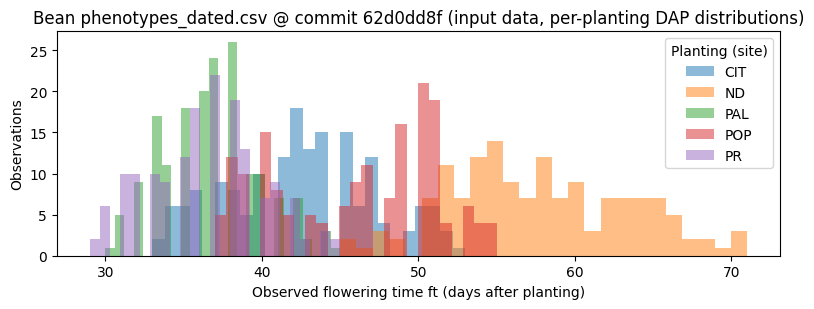

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

pheno = pd.read_csv(REPO_DIR / "pipeline/1_data/Beans/phenotypes_dated.csv")
print("shape:", pheno.shape, "| columns:", list(pheno.columns))
print("unique genotypes:", pheno["id"].nunique())
print("\nobservations per planting:")
print(pheno["Planting"].value_counts().sort_index().to_string())
print("\nft (days after planting) summary by planting:")
print(pheno.groupby("Planting")["ft"].describe().round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 3.2))
for planting, grp in pheno.groupby("Planting"):
    ax.hist(grp["ft"].dropna(), bins=25, alpha=0.5, label=str(planting))
ax.set_xlabel("Observed flowering time ft (days after planting)")
ax.set_ylabel("Observations")
ax.set_title("Bean phenotypes_dated.csv @ commit " + PINNED_SHA[:8] + " (input data, per-planting DAP distributions)")
ax.legend(title="Planting (site)")
fig.tight_layout()
plt.show()

## 3b · Input preview — daily weather per site

The mechanistic and photoperiod models drive development with daily temperatures. Per the
author's `documentation/DATA_FORMAT.md`, the per-site files
`pipeline/1_data/weather/{SITE}/weather.csv` use columns **`Period` (YYYY-MM-DD), `tmx`,
`tmn`** — the `year_col`/`tmax_col` names in `configs/beans.yaml` refer to the raw
combined source CSV, which the author's prepare step already split into these per-site
files. The five bean sites span latitudes 10.0°N (CIT) to 46.9°N (ND) per
`configs/beans.yaml`, which is what makes the photoperiod contrast identifiable. We
report each site's actual coverage; the files are ~100-day windows beginning the day
after planting (DAP 1), and we assert only the essential property — that each site's
weather reaches past its last phenotype observation date.

**日本語:** 5 サイトの daily weather（`DATA_FORMAT.md` のスキーマ: `Period`/`tmx`/`tmn`）
の行数・期間・温度範囲を確認します。ファイルは播種翌日 (DAP 1) 始まりの約 100 日分で、
最終観測日以降まで気象が続くことのみを assert します。
緯度は 10.0°N〜46.9°N で、これが光周期応答の識別を可能にします。

In [ ]:
import yaml as _yaml

weather_root = REPO_DIR / "pipeline/1_data/weather"
cfg = _yaml.safe_load((REPO_DIR / "configs/beans.yaml").read_text())
rows = []
for site in sorted(pheno["Planting"].astype(str).unique()):
    wf = weather_root / site / "weather.csv"
    assert wf.is_file(), f"missing weather for {site}"
    w = pd.read_csv(wf, parse_dates=["Period"])
    assert {"Period", "tmx", "tmn"} <= set(w.columns), f"unexpected weather schema: {list(w.columns)}"
    win = pheno[pheno["Planting"].astype(str) == site]
    cov_from = pd.Timestamp(win["Start_Date"].min())
    cov_to = pd.Timestamp(win["End_Date"].max())
    starts_dap1 = w["Period"].min() == cov_from + pd.Timedelta(days=1)
    covers_end = w["Period"].max() >= cov_to
    rows.append({
        "site": site,
        "days": len(w),
        "Period_min": str(w["Period"].min().date()),
        "Period_max": str(w["Period"].max().date()),
        "tmn_min (°C)": round(w["tmn"].min(), 1),
        "tmx_max (°C)": round(w["tmx"].max(), 1),
        "starts DAP 1": starts_dap1,
        "covers last obs date": covers_end,
        "lat (config)": cfg["locations"][site]["latitude"],
    })
wx = pd.DataFrame(rows)
print(wx.to_string(index=False))
assert bool(wx["covers last obs date"].all()), 'some site weather ends before its last phenotype observation'

site  days Period_min Period_max  tmn_min (°C)  tmx_max (°C)  starts DAP 1  covers last obs date  lat (config)
 CIT   100 2011-03-25 2011-07-02           4.6          38.5          True                  True          10.0
  ND   100 2012-05-17 2012-08-24           2.5          37.9          True                  True          46.9
 PAL   100 2011-11-12 2012-02-17          17.4          31.9          True                  True          18.2
 POP    99 2012-03-23 2012-06-29           8.9          30.5          True                  True          19.0
  PR   100 2012-02-07 2012-05-16          16.8          31.7          True                  True          18.2


## 4 · Run the author pipeline — bean CV2 (mechanistic runs; genomic methods auto-skip)

This executes the author's documented entry point verbatim
(README "Running both workflows" / QUICKSTART "First Run"):

```
python -m cgm_wgp.app --config configs/beans.yaml --run-joint --cv-scheme balanced_training_subset
```

What it does (`src/cgm_wgp/app.py::_run_cv_scheme`): for each of 5 repetitions (seed 42) it
splits each site's genotype×planting cells 80/20, writes per-fold train/test CSVs, then runs
`cgm_wgp.main_fit` per fold — mechanistic cardinal-β fit via `scipy.optimize.dual_annealing`,
GBLUP and RN-GBLUP via the R-loaded EVD, and (`--run-joint`) the CGM-WGP EM + L-BFGS-B joint
fit — then aggregates predictions, writes `combined/diagnostics/` metrics
(`cv_summary.csv`, `rep_summary.csv` with mean±std across reps) and `plots/obs_vs_pred_*.png`.

**Behavior when the EVD is absent:** `main_fit` catches EVD-load failures
(`try/except ... Warning: ... failed`) and continues without the genomic methods — the
pipeline still exits 0. That is the author's own documented behavior, and it is what this
run will show; the cell after this one makes the resulting method list explicit.

**`--maxiter` choice (documented adaptation):** the production default is 2000 dual-annealing
iterations per genotype per repetition. The author's own QUICKSTART uses `--maxiter 30` for the
first full pipeline run; we use a modest value to keep the notebook inside Colab's session
budget. Lowering `maxiter` trades optimizer convergence for wall time — treat the numbers as a
demonstration of the *pipeline mechanics*, not as converged paper-grade estimates.

**日本語:** 著者ドキュメントどおりのコマンドで CV2（各サイトの遺伝子型×環境セルを
80/20 分割 × 5 反復、seed 42）を実行します。EVD が読めない場合、パイプライン自身が
ゲノム手法を警告付きでスキップし終了コード 0 で完走するため、機構モデルのみの
結果になります（直後のセルで手法リストを明示します）。
`--maxiter` は dual_annealing の反復上限で、本ノートブックでは実行時間の制約から
著者 QUICKSTART 相当の小さい値に設定しています（収束度は実運用より低い）。

In [ ]:
import subprocess, sys, time, os
import pandas as pd
from pathlib import Path

MAXITER = 30  # documented adaptation; production default is 2000 (see markdown above)

env = dict(os.environ, PYTHONPATH="/content/CGM-WGP/src")
cmd = [sys.executable, "-m", "cgm_wgp.app",
       "--config", "configs/beans.yaml",
       "--run-joint",
       "--cv-scheme", "balanced_training_subset",
       "--maxiter", str(MAXITER)]
print("$ PYTHONPATH=/content/CGM-WGP/src " + " ".join(cmd) + "\n")

t0 = time.time()
proc = subprocess.Popen(cmd, cwd=str(REPO_DIR), env=env,
                        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                        text=True, bufsize=1)
for line in proc.stdout:
    print(line, end="")
proc.wait()
elapsed = time.time() - t0
assert proc.returncode == 0, f"pipeline exited {proc.returncode}"
print(f"\n=== pipeline finished in {elapsed/60:.1f} min (exit {proc.returncode}) ===")

runs_root = REPO_DIR / "pipeline/output/runs/Beans"
cv_dirs = [d for d in runs_root.rglob("*") if d.is_dir() and (d / "combined").is_dir()]
assert cv_dirs, "no CV run directory produced"
RUN_DIR = max(cv_dirs, key=lambda d: d.stat().st_mtime)
print("run dir:", RUN_DIR)

# Explicitly report which methods produced validation rows. With the EVD absent the
# author pipeline exits 0 but silently skips the genomic methods (its EVD-load
# failures are caught and warned, see main_fit.py) — make that visible here.
_methods = sorted(pd.read_csv(RUN_DIR / "combined/diagnostics/per_rep_validation.csv")["method"].unique())
print("\nmethods with validation rows:", _methods)
if not EVD_AVAILABLE:
    assert _methods == ["Mechanistic"], (
        f"unexpected methods without an EVD: {_methods}")
    print("\n>>> As expected with the EVD unavailable, ONLY the mechanistic method ran. "
          "The paper's GBLUP / RN-GBLUP / CGM-WGP comparison is NOT reproduced. <<<")

$ PYTHONPATH=/content/CGM-WGP/src /usr/bin/python3 -m cgm_wgp.app --config configs/beans.yaml --run-joint --cv-scheme balanced_training_subset --maxiter 30



  Pre-Phase-1 RN-GBLUP failed: R export failed (exit 1): Error in load("/content/CGM-WGP/pipeline/2_gmatrix/Beans/EVD.rda") : 
  bad restore file magic number (file may be corrupted) -- no data loaded
In addition: Warning message:
file ‘EVD.rda’ has magic number 'versi'
  Use of save versions prior to 2 is deprecated 
Execution halted

  Ensemble requires RN-GBLUP. Ensemble block will retry or skip.
Run output folder (structured): /content/CGM-WGP/pipeline/output/runs/Beans/multi/2026-10-26_03-26-07/folds/rep_1
Latitude map: {'CIT': 10.0, 'ND': 46.9, 'PAL': 18.2, 'POP': 19.0, 'PR': 18.2}
Loaded weather for 5 locations: ['CIT', 'ND', 'PAL', 'POP', 'PR']
Daylength data loaded for 655 genotype-planting combinations
Test phenotypes loaded: 163 held-out cells across 5 environments (used for validation, not fitting)
Augmented T_dict with 270 (genotype, test-env) cells using ref_temps (weather-only, no observations leaked)
Augmented T_dict with 2 unseen-genotype entries (10 cells) from ref_te

Completed: 185 succeeded, 0 failed
  RIJC_001: alpha=3.555877 beta=2.257358 loss=4.676003e-20
  RIJC_003: alpha=6.284426 beta=7.999999 loss=8.078015e+01
  RIJC_004: alpha=3.094893 beta=3.683638 loss=1.757274e-09
  RIJC_005: alpha=1.836015 beta=2.013386 loss=4.533493e+00
  RIJC_006: alpha=5.784686 beta=7.413240 loss=4.184211e+01
  RIJC_007: alpha=6.225281 beta=7.919083 loss=5.462695e+00
  RIJC_008: alpha=3.309051 beta=7.630357 loss=0.000000e+00
  RIJC_009: alpha=2.165724 beta=2.008362 loss=3.373199e+00
  RIJC_012: alpha=6.177804 beta=8.000000 loss=6.071346e+01
  RIJC_013: alpha=5.156681 beta=6.157945 loss=1.283761e+01
  RIJC_014: alpha=6.373296 beta=7.999999 loss=1.285197e+02
  RIJC_015: alpha=5.563673 beta=7.045763 loss=3.228928e+01
  RIJC_016: alpha=1.861098 beta=1.580593 loss=3.050001e-01
  RIJC_018: alpha=1.733347 beta=2.702144 loss=7.831300e-17
  RIJC_019: alpha=5.815161 beta=8.000000 loss=1.507990e+01
  RIJC_020: alpha=2.325211 beta=2.739621 loss=1.161442e+01
  RIJC_021: alpha=4.2

Completed: 185 succeeded, 0 failed

  PHOTOPERIOD STAGE: Logistic3 (Messina, DAP-error loss)
  a bounds: (0.1, 5.0)
  b bounds: (-5.0, 5.0)
  d bounds: (10.0, 18.0) (daylength hours)
  photo_type: short_day (applies sign constraint on b)
  Population logistic3 photoperiod (Messina, via photo-only fit):
    a=4.5567, b=0.1301, d=15.178h
    Floor: 1/(1+a) = 0.1800
    Photo-only loss (SSE/n): 10.02  |  Temp-only baseline: 1850.36
    -> Photoperiod IMPROVES fit (delta = 1840.33)
    DL=10h: F(DL) = 0.3009
    DL=12h: F(DL) = 0.2491
    DL=14h: F(DL) = 0.2037
    DL=16h: F(DL) = 0.1647

  ── Dual-threshold mech+photo mode ──
  H_thermal computed for 185 genotypes
  H_photo computed for 185 genotypes
  Dual-threshold recomputed for 185 genotypes (skipped 0)
  Binding channel: thermal=329, photo=596 cells
  No photoperiod signal (improvement=1840.33), skipping — temp-only predictions
Training residual MSE: 5.61 days² (RMSE=2.37)
GBLUP-LOO mech MSE: unavailable, using training_mse=5.61
Env-

  bad restore file magic number (file may be corrupted) -- no data loaded
In addition: Warning message:
file ‘EVD.rda’ has magic number 'versi'
  Use of save versions prior to 2 is deprecated 
Execution halted



...

/content/CGM-WGP/src/cgm_wgp/app.py:1849: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r_val, _ = pearsonr(o, p)


/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
/content/CGM-WGP/src/cgm_wgp/app.py:1264: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  sr, _ = spearmanr(obs_p, pred_p)


/content/CGM-WGP/src/cgm_wgp/app.py:1939: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  r_val, _ = pearsonr(obs, pred)



  balanced_training_subset CV2:
    train_fraction=0.8, repetitions=5, random_seed=42

  CV Scheme: balanced_training_subset (5 folds)
  Output: /content/CGM-WGP/pipeline/output/runs/Beans/multi/2026-10-26_03-26-07

  Rep 'rep_1' (seed=42): train=655 cells, test=163 cells, envs=5
RUN: /usr/bin/python3 -m cgm_wgp.main_fit --phenotypes /content/CGM-WGP/pipeline/output/runs/Beans/multi/2026-10-26_03-26-07/folds/rep_1/train_phenotypes.csv --weather /content/CGM-WGP/pipeline/1_data/weather --Tb 10.0 --Topt 25.0 --Tc 38.0 --maxiter 30 --seed 42 --crop Beans --max-posterior-samples 200 --workers 0 --evd-path /content/CGM-WGP/pipeline/2_gmatrix/Beans/EVD.rda --photo-model logistic3 --photo-n-min-bounds 6.0 14.0 --photo-n-opt-bounds 8.0 16.0 --photo-a-bounds 0.1 5.0 --photo-b-bounds -5.0 5.0 --photo-d-bounds 10.0 18.0 --rn-photoperiod --mech-dual-threshold --latitude-map {"CIT": 10.0, "ND": 46.9, "PAL": 18.2, "POP": 19.0, "PR": 18.2} --run-joint --joint-photo-enabled --joint-Theta-bounds 5.0 2


=== pipeline finished in 9.4 min (exit 0) ===
run dir: /content/CGM-WGP/pipeline/output/runs/Beans/multi/latest

methods with validation rows: ['Mechanistic']

>>> As expected with the EVD unavailable, ONLY the mechanistic method ran. The paper's GBLUP / RN-GBLUP / CGM-WGP comparison is NOT reproduced. <<<


## 5 · Validation comparison — methods that produced results

The combined step aggregates every repetition's `diagnostics/validation_comparison.csv` into
`per_rep_validation.csv` (one row per rep × method) and `rep_summary.csv` (per-method mean ±
std of MAE, RMSE, bias, and within-N-day hit rates over all held-out genotype×environment
cells). `cv_summary.csv` additionally holds overall and per-environment RMSE and Pearson r.
All values below come from this executed run only.

With the genomic inputs unavailable (see the warning at the top), only the **Mechanistic**
method produces rows. For orientation, the paper's Table 1 (five-fold averages, beans CV2
sparse testing) reports: Mechanistic CGM **r = 0.83, RMSE = 7.5 d**; GBLUP r = 0.34, RMSE 8.5;
RN-GBLUP r = 0.93, RMSE 3.2; CGM-WGP r = 0.90, RMSE 4.7 — the latter three are exactly the
rows this run cannot produce.

**日本語:** 各反復の検証指標を集計した `per_rep_validation.csv`（反復×手法ごと）と、
手法ごとの mean±std まとめ `rep_summary.csv`、さらに環境別の RMSE・Pearson r を含む
`cv_summary.csv` を表示します。ゲノム入力が入手不可のため、行が存在するのは
**Mechanistic のみ**です（参考: 論文 Table 1 の beans CV2 5 平均値は
Mechanistic r=0.83/RMSE=7.5 d、RN-GBLUP r=0.93/RMSE=3.2 など）。

In [ ]:
import pandas as pd
from IPython.display import display

per_rep = pd.read_csv(RUN_DIR / "combined/diagnostics/per_rep_validation.csv")
summary = pd.read_csv(RUN_DIR / "combined/diagnostics/rep_summary.csv")
cv_summary = pd.read_csv(RUN_DIR / "combined/cv_summary.csv")

print("=== Per-method mean ± std across the 5 CV2 repetitions (all held-out cells) ===")
display(summary)

print("\n=== cv_summary.csv (overall + per-environment RMSE / Pearson r) ===")
display(cv_summary)

print("\n=== Per-repetition validation comparison (raw) ===")
display(per_rep)

=== Per-method mean ± std across the 5 CV2 repetitions (all held-out cells) ===


,method,n_evaluated_mean,n_evaluated_std,mae_mean,mae_std,rmse_mean,rmse_std,bias_mean,bias_std,median_error_mean,median_error_std,within_3d_mean,within_3d_std,within_5d_mean,within_5d_std,within_7d_mean,within_7d_std,within_10d_mean,within_10d_std
0,Mechanistic,162.0,2.236,8.592,0.905,15.414,2.223,7.138,0.911,3.2,0.447,68.8,4.712,104.0,2.236,120.8,2.95,133.0,2.121



=== cv_summary.csv (overall + per-environment RMSE / Pearson r) ===


,crop,cv_scheme,method,planting,n,rmse,pa
0,Beans,balanced_training_subset,Mechanistic,Overall,810,16.15,0.5311
1,Beans,balanced_training_subset,Mechanistic,CIT,169,4.54,NaN
2,Beans,balanced_training_subset,Mechanistic,ND,144,5.67,NaN
3,Beans,balanced_training_subset,Mechanistic,PAL,169,6.65,NaN
4,Beans,balanced_training_subset,Mechanistic,POP,169,33.43,-0.0135
5,Beans,balanced_training_subset,Mechanistic,PR,159,6.50,NaN



=== Per-repetition validation comparison (raw) ===


,method,train_plantings,predict_plantings,n_evaluated,mae,rmse,bias,median_error,within_3d,within_5d,within_7d,within_10d,center_used,description,rep
0,Mechanistic,"CIT, ND, PAL, POP, PR","CIT, ND, PAL, POP, PR",158,7.54,12.94,6.06,3.0,68,105,118,132,"CIT=43.5, ND=61.2, PAL=46.2, POP=57.2, PR=42.4...","Top-K dual annealing of (alpha, beta) per geno...",rep_1
1,Mechanistic,"CIT, ND, PAL, POP, PR","CIT, ND, PAL, POP, PR",163,8.04,13.99,6.69,3.0,71,101,118,135,"CIT=45.5, ND=61.5, PAL=42.5, POP=62.1, PR=42.7...","Top-K dual annealing of (alpha, beta) per geno...",rep_2
2,Mechanistic,"CIT, ND, PAL, POP, PR","CIT, ND, PAL, POP, PR",163,8.43,14.87,7.01,4.0,61,107,121,130,"CIT=43.6, ND=59.6, PAL=45.2, POP=62.5, PR=43.1...","Top-K dual annealing of (alpha, beta) per geno...",rep_3
3,Mechanistic,"CIT, ND, PAL, POP, PR","CIT, ND, PAL, POP, PR",163,9.10,16.78,7.43,3.0,71,104,125,133,"CIT=44.6, ND=58.9, PAL=46.8, POP=61.8, PR=43.5...","Top-K dual annealing of (alpha, beta) per geno...",rep_4
4,Mechanistic,"CIT, ND, PAL, POP, PR","CIT, ND, PAL, POP, PR",163,9.85,18.49,8.50,3.0,73,103,122,135,"CIT=43.9, ND=57.3, PAL=42.9, POP=65.3, PR=47.9...","Top-K dual annealing of (alpha, beta) per geno...",rep_5


## 6 · Predicted vs observed flowering DAP — author-generated scatter plots

The pipeline saves one `obs_vs_pred_<method>.png` per method that produced predictions in
the run's `plots/` directory (`src/cgm_wgp/app.py::_plot_obs_vs_pred`: observed vs
predicted DAP colored by planting, with the Pearson r annotated). We display the saved
PNGs directly — these are the pipeline's own outputs from this executed run, not re-plots.
In this partial run only the mechanistic plot is expected.

**日本語:** パイプラインが保存した `obs_vs_pred_*.png`（観測 DAP vs 予測 DAP、
環境別に色分け、Pearson r 付き）をそのまま表示します。今回の部分実行では
Mechanistic の図のみが生成されます。

saved plots: ['obs_vs_pred_mechanistic.png', 'obs_vs_pred_raw_mechanistic.png']


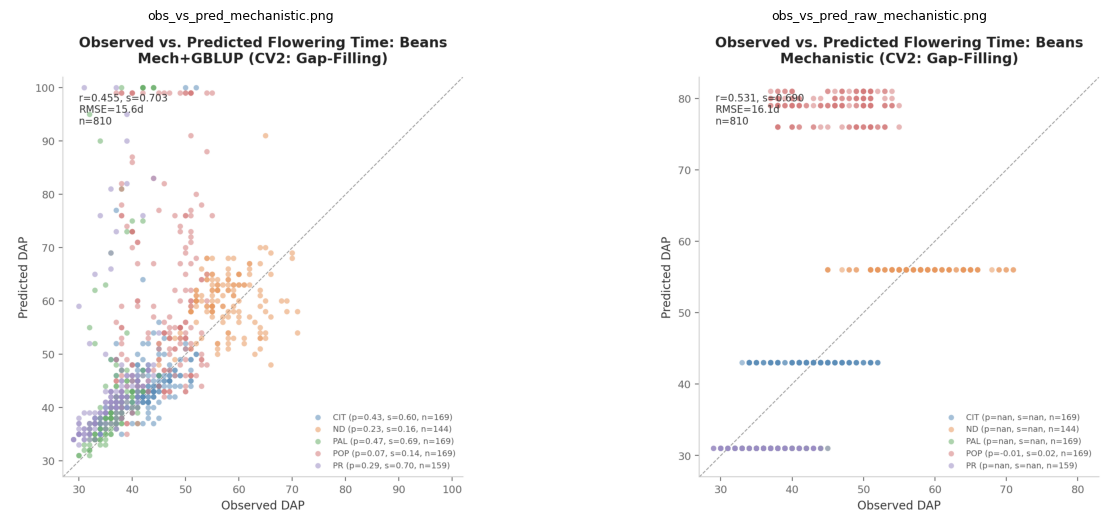

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

plots_dir = RUN_DIR / "plots"
saved = sorted(plots_dir.glob("obs_vs_pred_*.png"))
print("saved plots:", [p.name for p in saved] if saved else "none")
if saved:
    ncol = 2
    nrow = (len(saved) + ncol - 1) // ncol
    fig, axes = plt.subplots(nrow, ncol, figsize=(7 * ncol, 5.4 * nrow))
    axes = [axes] if nrow * ncol == 1 else list(axes.flat)
    for ax in axes:
        ax.axis("off")
    for ax, png in zip(axes, saved):
        ax.imshow(mpimg.imread(str(png)))
        ax.set_title(png.name, fontsize=9)
    fig.tight_layout()
    plt.show()
else:
    print("No obs_vs_pred plots were generated by this run.")

## 7 · Interpretation — against the paper's numbers

The paper's abstract states that (a) **RN-GBLUP was most accurate under sparse testing**,
and (b) **CGM-WGP wins for untested environments and G×E combinations** (bean: r = 0.86,
RMSE = 5.2 d — a different, harder scenario than this CV2 scheme). Its Table 1 (five-fold
averages, beans CV2) reports the mechanistic CGM baseline at **r = 0.83, RMSE = 7.5 d**.

Compare this executed run's mechanistic `cv_summary` / `rep_summary` rows above with that
CGM baseline, keeping in mind: `--maxiter 30` is a reduced optimizer budget, and one crop ×
one scheme × 5 repetitions validates **pipeline mechanics**, not dataset-level conclusions.
The genomic comparison — the paper's central claim — **could not be run**: the required
genomic inputs are not publicly available (verified 2026-10-26):
1. `pipeline/2_gmatrix/Beans/EVD.rda` and `Gmatrix.rda`: Git-LFS pointer files whose
   objects return **404 "Object does not exist"** from the author's LFS storage
   (`git lfs pull`) and from the pinned media URL.
2. `pipeline/1_data/Beans/3. RIJC Data.xlsx` (marker matrix that would allow regenerating
   the EVD with the author's own `prepare_pipeline._prepare_markers_tier`): dangling LFS
   pointer, same 404s.
3. The repository has a single branch (`main`), no releases, no forks, and no other
   deposits; the paper's Data Availability statement reads "available from the
   corresponding author on reasonable request" (Research Square preprint v1 PDF).

**日本語:** 論文 Table 1（beans CV2、5 平均）では機構モデル CGM が r=0.83 /
RMSE=7.5 d、RN-GBLUP が r=0.93 / RMSE=3.2 d などと報告されています。この実行は
maxiter を削減した 1 作物 × 1 方式 × 5 反復の**動作確認**であり、データセット
レベルの検証ではありません。論文の中心であるゲノム手法の比較は、必要なゲノム
入力が公開入手不可能であること（2026-10-26 検証、上記 1–3）のため実行できませんでした。

## 8 · Sources, validation record, and limitations

**Sources (all retrieved in this notebook's runtime):**
- Paper: Research Square preprint v1, DOI 10.21203/rs.3.rs-9890445/v1 (public manuscript PDF;
  Table 1 numbers cited above were read from it).
- Code: `melycg2001/CGM-WGP` @ `62d0dd8f6cf67de5857149cfb1a2b1a8ef2dc4ab` (author's single
  commit; no license file — "License to be determined"; prototype).
- Data: bean phenotypes + per-site daily weather from the same pinned commit (plain git
  blobs). The bean genomic EVD/G-matrix and the raw marker xlsx are Git-LFS pointers whose
  objects are absent from the author's LFS storage (verified 2026-10-26) — see section 7.

**Adaptations (documented):** `PYTHONPATH=src` (the prototype ships no package installer);
base-R via apt for the author's `load_evd()` Rscript subprocess (unused here because the
EVD payload is unavailable); `--maxiter 30` instead of the production default 2000 (author
QUICKSTART's first-run value) to fit Colab's session budget.

**Limitations:** single crop, single CV scheme, reduced optimizer budget, and — critically —
the genomic half of the method comparison is **missing**, not merely unexecuted: the three
genomic methods are skipped by the author pipeline's own handling when the EVD cannot be
loaded. One executed example ≠ dataset-level reproduction.

**日本語:** 使用したのは論文 v1・著者コード `62d0dd8`・同コミットのマメデータの
みです。適応点（PYTHONPATH、R の apt 導入、maxiter 縮小）と限界（1 作物・1 CV 方式・
低反復、および**ゲノム手法が入力欠落のため実行不可**）は本文のとおりです。
実行 1 例はデータセットレベルの再現ではありません。